# GOAT temperature audit: does regularization explain the hub effect?

**Run with the `ds` kernel.** This is a small diagnostic on existing development pairs, not a new confirmation experiment.

**Default:** 5 pairs each for Chung–Lu and PAPER, budgets **8 and 10**, two fixed rules (**top degree** and **hub-free top degree**), and regularizers **100, 300, 600**: **120 GOAT calls**. All graphs have 600 vertices and mean degree about 16; rho is 0.45 for Chung–Lu and 0.40 on PAPER's ER background. The graph pairs, seed sets, solver randomness, initialization and stopping tolerances stay fixed while regularization changes. Every requested run is evaluated, including after a success.

For a short trial, set `PAIR_INDICES = (0,)`, `MODELS = ('chung_lu',)` and `OUTPUT_DIR = ... / 'temperature_audit_trial'`. Use a different folder for the full configuration. To see a runtime estimate before committing, run just the first model/pair trial. Completed calls checkpoint automatically; the identical configuration resumes. The pair list can be extended without changing the other settings.

The runner uses the **installed graspologic solver unchanged**, adding diagnostic hooks only. No alternative gradient normalization is introduced. Runs are sequential because the hooks temporarily instrument private APIs. Avoid launching another matching run concurrently in this same Python kernel.


In [1]:
from pathlib import Path
import os
import sys
import tempfile

os.environ.setdefault('NUMBA_CACHE_DIR', str(Path(tempfile.gettempdir()) / 'sgm_numba_cache'))
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'sgm_matplotlib_cache'))
ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / 'selection_rule_comparison' / 'archive' / 'temperature_audit.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open the notebook from inside the Seeded-Graph-Matching repository.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from selection_rule_comparison.archive import temperature_audit as audit

MODELS = ('chung_lu', 'paper_pa')
PAIR_INDICES = tuple(range(5))  # existing round-1 development pairs, not newly selected by outcome
BUDGETS = (8, 10)
REGULARIZERS = (100, 300, 600)   # 300 is the previous setting for both default graph models
BLAS_THREADS = 3               # matches round-1 comparisons
RUN_EXPERIMENTS = True         # False = load saved results only
RETRY_ERRORS = False           # True retries recorded errors with the identical scientific settings
OUTPUT_DIR = ROOT / 'selection_rule_comparison' / 'data' / 'temperature_audit'
SOLVER = dict(max_iter=100, tol=0.01, transport_tol=0.05, transport_max_iter=5000)
N_BOOTSTRAP = 2000
RANDOM_STATE = 2026
SAVE_FIGURES = True
COLORS = {'top_degree': '#222222', 'hub_free_top_degree': '#E67E22'}

planned = len(MODELS) * len(PAIR_INDICES) * len(BUDGETS) * len(REGULARIZERS) * 2
print(f'{planned} calls: {len(MODELS)} models × {len(PAIR_INDICES)} pairs × '
      f'{len(BUDGETS)} budgets × {len(REGULARIZERS)} regularizers × 2 rules')


120 calls: 2 models × 5 pairs × 2 budgets × 3 regularizers × 2 rules


## 1. What this parameter means

The installed implementation divides the transport-step gradient by its largest absolute entry. For gradient $G$ and `transport_regularizer` $r$, its Sinkhorn kernel is

$$K_{ij} = \exp\left(r G_{ij}/\max |G|\right).$$

Thus **larger `r` makes preferences sharper**, while smaller `r` makes them softer. In raw-gradient units, the magnitude of the effective entropic regularization is $\epsilon=\max|G|/r$. This is why the parameter name should not be interpreted as a conventional temperature without checking the implementation.

**Hypothesis:** hubs may increase an extreme gradient entry, compressing the remaining normalized scores and changing transport sharpness. A regularization sweep tests sensitivity to sharpness; it cannot by itself prove that global maximum normalization causes the hub effect.

The exact installed transport-method source is saved in `settings.json` below. For PAPER, rho applies to its noisy background; its PA tree remains shared.


In [2]:
import inspect
print(inspect.getsource(audit.wrappers._GraphMatchSolver.linear_sum_transport))


    def linear_sum_transport(
        self,
        P: np.ndarray,
    ) -> np.ndarray:
        maximize = self.maximize
        reg = self.transport_regularizer

        power = -1 if maximize else 1
        lamb = reg / np.max(np.abs(P))
        ones = np.ones(P.shape[0])
        P_eps, log = sinkhorn(
            ones,
            ones,
            P,
            power / lamb,
            stopThr=self.transport_tol,
            numItermax=self.transport_max_iter,
            log=True,
            warn=False,
        )
        if log["niter"] == self.transport_max_iter - 1:
            warnings.warn(
                "Sinkhorn-Knopp algorithm for solving linear sum transport "
                f"problem did not converge. The final error was {log['err'][-1]} "
                f"and the `transport_tol` was {self.transport_tol}. "
                "You may want to consider increasing "
                "`transport_regularizer`, increasing `transport_max_iter`, or this "
                "cou

## 2. Run or resume

Exact round-1 pairs are regenerated and hash-checked, then frozen with their seed sets in the new output directory. Each completed call is written atomically, along with its final permutation and an iteration trace. Settings, source hashes and package versions protect against mixing different experiments. Existing project datasets are read only.

A recorded solver error is not counted as a matching failure. Set `RETRY_ERRORS = True` to retry error cells under the same configuration. Changes to regularizers, budgets, models, numerical settings or source versions require a new `OUTPUT_DIR`.


In [3]:
if RUN_EXPERIMENTS:
    runs, trace = audit.run_audit(
        models=MODELS, pair_indices=PAIR_INDICES, budgets=BUDGETS, regularizers=REGULARIZERS,
        output_dir=OUTPUT_DIR, blas_threads=BLAS_THREADS, retry_errors=RETRY_ERRORS, **SOLVER)
else:
    runs, trace = audit.load_results(OUTPUT_DIR, models=MODELS, pair_indices=PAIR_INDICES)

expected_keys = {(m, p, k, rule, float(r)) for m in MODELS for p in PAIR_INDICES
                 for k in BUDGETS for rule in audit.RULES for r in REGULARIZERS}
keys = ['model', 'pair_index', 'budget', 'rule', 'regularizer']
if runs.duplicated(keys).any():
    raise ValueError('Duplicate result cells.')
seen_keys = set(runs[keys].itertuples(index=False, name=None))
print(f'Available: {len(seen_keys & expected_keys)}/{len(expected_keys)} requested cells')
print('Missing cells:', len(expected_keys - seen_keys))
runs = runs[runs[keys].apply(tuple, axis=1).isin(expected_keys)].copy()
display(runs.groupby(['model', 'status']).size().rename('calls').to_frame())
errors = runs[runs['status'] != 'ok']
if not errors.empty:
    display(errors[[*keys, 'error']])
valid = runs[runs['status'] == 'ok'].copy()
if valid.empty:
    raise RuntimeError('No successful solver calls are available for analysis.')
if len(valid) < len(expected_keys):
    print('PARTIAL AUDIT: comparisons below use only paired available results; finish missing/error cells before conclusions.')
if not trace.empty:
    trace = trace.merge(valid[keys], on=keys, how='inner', validate='many_to_one')


Requested 120 GOAT runs; completed runs will be reused.
chung_lu, pair 0: 12/120 cells saved; elapsed 0.5 min; about 4.2 min remaining
chung_lu, pair 1: 24/120 cells saved; elapsed 1.0 min; about 3.9 min remaining
chung_lu, pair 2: 36/120 cells saved; elapsed 1.5 min; about 3.4 min remaining
chung_lu, pair 3: 48/120 cells saved; elapsed 1.8 min; about 2.8 min remaining
chung_lu, pair 4: 60/120 cells saved; elapsed 2.2 min; about 2.2 min remaining
paper_pa, pair 0: 72/120 cells saved; elapsed 2.6 min; about 1.7 min remaining
paper_pa, pair 1: 84/120 cells saved; elapsed 3.0 min; about 1.3 min remaining
paper_pa, pair 2: 96/120 cells saved; elapsed 3.4 min; about 0.9 min remaining
paper_pa, pair 3: 108/120 cells saved; elapsed 4.1 min; about 0.5 min remaining
paper_pa, pair 4: 120/120 cells saved; elapsed 4.5 min; about 0.0 min remaining
Audit finished: 120/120 successful calls, 0 errors. Saved to /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/data/temperature_au

,,calls
model,status,
chung_lu,ok,60
paper_pa,ok,60


## 3. Numerical checks and reproduction of the old setting

Warnings, inner iteration limits, outer convergence and doubly-stochastic marginal errors are reported separately. A clean flag requires all checks to pass. Accuracy can still be recorded for a flagged run, but a parameter setting with numerical problems needs investigation before scientific interpretation.

At the old regularizer (300 for these two models), available saved top-degree and hub-free runs are compared with their previous accuracy and objective. Solver randomness and numerical settings are held fixed. This verifies that instrumentation and regenerated seed sets reproduce the earlier experiment. No matching outcomes are used to choose the pair list.


In [4]:
checks = valid.groupby(['model', 'regularizer', 'rule']).agg(
    calls=('accuracy', 'size'), clean_calls=('numerically_clean', 'sum'),
    outer_nonconverged=('converged', lambda s: int((~s.astype(bool)).sum())),
    calls_with_warnings=('warning_count', lambda s: int((s > 0).sum())),
    inner_limit_calls=('inner_limit_reached', 'sum'),
    largest_transport_error=('max_transport_marginal_error', 'max'),
    mean_iterations=('n_iter', 'mean'), mean_seconds=('runtime_seconds', 'mean'))
display(checks.round(4))
if 'reference_accuracy_match' in valid:
    refs = valid[valid['reference_accuracy_match'].notna()]
    display(refs.groupby(['model', 'rule']).agg(
        checks=('reference_accuracy_match', 'size'), accuracy_matches=('reference_accuracy_match', 'sum'),
        objective_matches=('reference_objective_match', 'sum')))
    if not refs['reference_accuracy_match'].astype(bool).all() or not refs['reference_objective_match'].astype(bool).all():
        print('REFERENCE MISMATCH: inspect these calls before interpreting the audit.')
checks.to_csv(OUTPUT_DIR / 'numerical_checks.csv')


calls  clean_calls  \
model    regularizer rule                                      
chung_lu 100.0       hub_free_top_degree     10           10   
                     top_degree              10           10   
         300.0       hub_free_top_degree     10           10   
                     top_degree              10           10   
         600.0       hub_free_top_degree     10           10   
                     top_degree              10           10   
paper_pa 100.0       hub_free_top_degree     10           10   
                     top_degree              10           10   
         300.0       hub_free_top_degree     10           10   
                     top_degree              10           10   
         600.0       hub_free_top_degree     10           10   
                     top_degree              10            9   

                                          outer_nonconverged  \
model    regularizer rule                                      
chung_lu 100.0       hub_free_top_degree                   0   
                     top_degree                            0   
         300.0       hub_free_top_degree                   0   
                     top_degree                            0   
         600.0       hub_free_top_degree                   0   
                     top_degree                            0   
paper_pa 100.0       hub_free_top_degree                   0   
                     top_degree                            0   
         300.0       hub_free_top_degree                   0   
                     top_degree                            0   
         600.0       hub_free_top_degree                   0   
                     top_degree                            0   

                                          calls_with_warnings  \
model    regularizer rule                                       
chung_lu 100.0       hub_free_top_degree                    0   
                     top_degree                             0   
         300.0       hub_free_top_degree                    0   
                     top_degree                             0   
         600.0       hub_free_top_degree                    0   
                     top_degree                             0   
paper_pa 100.0       hub_free_top_degree                    0   
                     top_degree                             0   
         300.0       hub_free_top_degree                    0   
                     top_degree                             0   
         600.0       hub_free_top_degree                    0   
                     top_degree                             1   

                                          inner_limit_calls  \
model    regularizer rule                                     
chung_lu 100.0       hub_free_top_degree                  0   
                     top_degree                           0   
         300.0       hub_free_top_degree                  0   
                     top_degree                           0   
         600.0       hub_free_top_degree                  0   
                     top_degree                           0   
paper_pa 100.0       hub_free_top_degree                  0   
                     top_degree                           0   
         300.0       hub_free_top_degree                  0   
                     top_degree                           0   
         600.0       hub_free_top_degree                  0   
                     top_degree                           1   

                                          largest_transport_error  \
model    regularizer rule                                           
chung_lu 100.0       hub_free_top_degree                   0.0329   
                     top_degree                            0.0242   
         300.0       hub_free_top_degree                   0.0350   
                     top_degree                            0.0305   
         600.0       hub_free_top_degree

checks accuracy_matches objective_matches
model    rule                                                          
chung_lu hub_free_top_degree      10               10                10
         top_degree               10               10                10
paper_pa hub_free_top_degree      10               10                10
         top_degree               10               10                10

## 4. Matching performance and the hub-free advantage

Success means at least 90% accuracy on unseeded vertices. Curves average over the same requested pairs. Dashed lines show normalized first-step transport entropy (0 = sharp; 1 = uniform). The vertical grey line marks the old regularizer 300.

The paired table compares **hub-free minus top degree** at the same pair, budget and regularizer; positive differences favor avoiding hubs. Intervals resample pairs. Five pairs give only an exploratory diagnostic. Both rules must use the same regularizer: do not choose a separate best value for each rule on this audit and call it a held-out improvement.


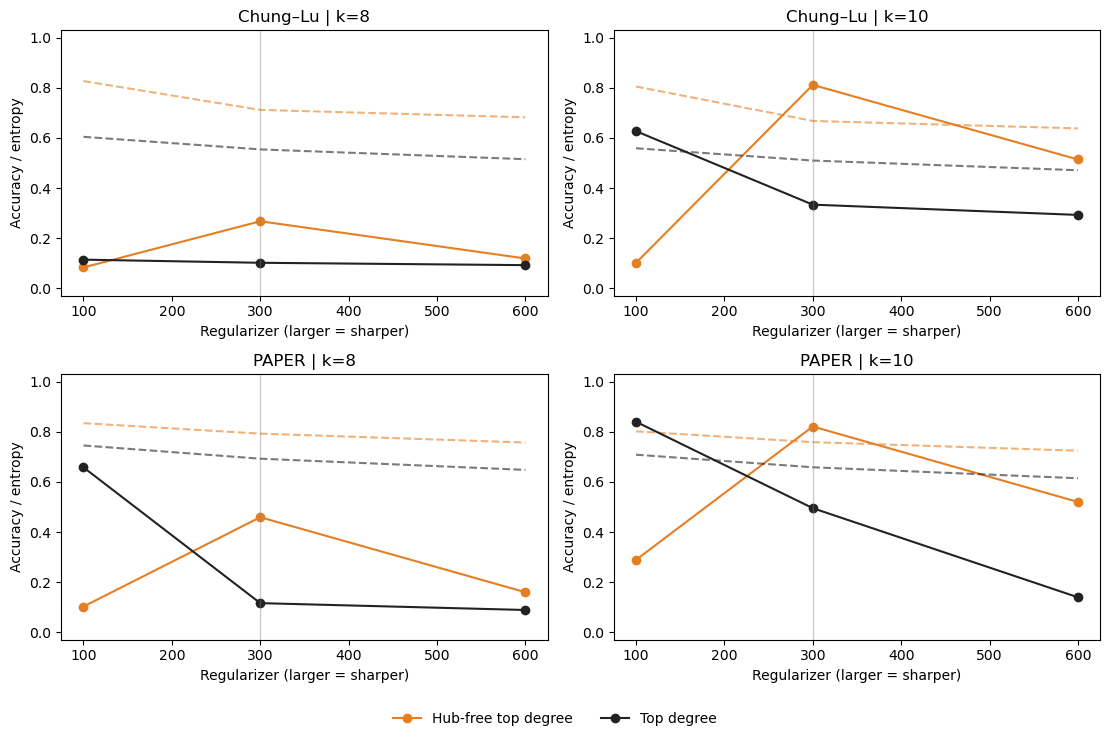

pairs  success_rate  \
model    budget regularizer rule                                       
chung_lu 8      100.0       hub_free_top_degree      5           0.0   
                            top_degree               5           0.0   
                300.0       hub_free_top_degree      5           0.2   
                            top_degree               5           0.0   
                600.0       hub_free_top_degree      5           0.0   
                            top_degree               5           0.0   
         10     100.0       hub_free_top_degree      5           0.0   
                            top_degree               5           0.6   
                300.0       hub_free_top_degree      5           0.8   
                            top_degree               5           0.2   
                600.0       hub_free_top_degree      5           0.4   
                            top_degree               5           0.2   
paper_pa 8      100.0       hub_free_top_degree      5           0.0   
                            top_degree               5           0.6   
                300.0       hub_free_top_degree      5           0.4   
                            top_degree               5           0.0   
                600.0       hub_free_top_degree      5           0.0   
                            top_degree               5           0.0   
         10     100.0       hub_free_top_degree      5           0.2   
                            top_degree               5           0.8   
                300.0       hub_free_top_degree      5           0.8   
                            top_degree               5           0.4   
                600.0       hub_free_top_degree      5           0.4   
                            top_degree               5           0.0   

                                                 mean_accuracy  \
model    budget regularizer rule                                 
chung_lu 8      100.0       hub_free_top_degree          0.083   
                            top_degree                   0.114   
                300.0       hub_free_top_degree          0.267   
                            top_degree                   0.101   
                600.0       hub_free_top_degree          0.119   
                            top_degree                   0.092   
         10     100.0       hub_free_top_degree          0.101   
                            top_degree                   0.627   
                300.0       hub_free_top_degree          0.812   
                            top_degree                   0.334   
                600.0       hub_free_top_degree          0.514   
                            top_degree                   0.293   
paper_pa 8      100.0       hub_free_top_degree          0.102   
                            top_degree                   0.658   
                300.0       hub_free_top_degree          0.459   
                            top_degree                   0.116   
                600.0       hub_free_top_degree          0.159   
                            top_degree                   0.089   
         10     100.0       hub_free_top_degree          0.289   
                            top_degree                   0.840   
                300.0       hub_free_top_degree          0.821   
                            top_degree                   0.495   
                600.0       hub_free_top_degree          0.520   
                            top_degree                   0.139   

                                                 first_direction_accuracy  \
model    budget regularizer rule                                            
chung_lu 8      100.0       hub_free_top_degree                     0.040   
                            top_degree                              0.037   
                300.0       hub_free_top_degree                     0.035   
                            top_degree                              0.038 

,model,budget,regularizer,metric,pairs,difference,low,high
0,chung_lu,8,100.0,accuracy,5,-0.031,-0.099,0.018
1,chung_lu,8,100.0,success,5,0.000,0.000,0.000
2,chung_lu,8,300.0,accuracy,5,0.166,-0.019,0.511
3,chung_lu,8,300.0,success,5,0.200,0.000,0.600
4,chung_lu,8,600.0,accuracy,5,0.027,-0.014,0.096
5,chung_lu,8,600.0,success,5,0.000,0.000,0.000
6,chung_lu,10,100.0,accuracy,5,-0.526,-0.892,-0.147
7,chung_lu,10,100.0,success,5,-0.600,-1.000,-0.200
8,chung_lu,10,300.0,accuracy,5,0.478,0.105,0.836
9,chung_lu,10,300.0,success,5,0.600,0.200,1.000


In [5]:
def save_figure(fig, name):
    if SAVE_FIGURES:
        folder = OUTPUT_DIR / 'figures'
        folder.mkdir(exist_ok=True)
        fig.savefig(folder / f'{name}.png', dpi=170, bbox_inches='tight')

models_present = [m for m in MODELS if m in set(valid['model'])]
budgets_present = sorted(valid['budget'].unique())
fig, axes = plt.subplots(len(models_present), len(budgets_present),
                         figsize=(5.6*len(budgets_present), 3.7*len(models_present)), squeeze=False)
for i, model in enumerate(models_present):
    for j, budget in enumerate(budgets_present):
        ax = axes[i, j]
        sub = valid[(valid['model'] == model) & (valid['budget'] == budget)]
        for rule, group in sub.groupby('rule'):
            mean = group.groupby('regularizer')[['accuracy', 'success', 'first_transport_entropy']].mean()
            ax.plot(mean.index, mean['accuracy'], '-o', color=COLORS[rule], label=audit.LABELS[rule])
            ax.plot(mean.index, mean['first_transport_entropy'], '--', color=COLORS[rule], alpha=.6)
        ax.axvline(300, color='grey', alpha=.4, linewidth=1)
        ax.set(title=f'{audit.MODEL_LABELS[model]} | k={budget}', xlabel='Regularizer (larger = sharper)',
               ylabel='Accuracy / entropy', ylim=(-.03, 1.03))
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False)
fig.tight_layout(rect=(0,.05,1,1))
save_figure(fig, 'accuracy_and_entropy')
plt.show()

summary = valid.groupby(['model', 'budget', 'regularizer', 'rule']).agg(
    pairs=('pair_index', 'nunique'), success_rate=('success', 'mean'), mean_accuracy=('accuracy', 'mean'),
    first_direction_accuracy=('first_direction_accuracy', 'mean'),
    first_transport_entropy=('first_transport_entropy', 'mean'), final_soft_entropy=('final_soft_entropy', 'mean'))
display(summary.round(3))
summary.to_csv(OUTPUT_DIR / 'performance_summary.csv')

generator = np.random.default_rng(RANDOM_STATE)
paired_rows = []
for (model, budget, regularizer), group in valid.groupby(['model', 'budget', 'regularizer']):
    for metric in ['accuracy', 'success']:
        wide = group.pivot(index='pair_index', columns='rule', values=metric)
        if not set(audit.RULES).issubset(wide.columns):
            continue
        wide = wide[list(audit.RULES)].dropna().astype(float)
        if wide.empty:
            continue
        difference = (wide['hub_free_top_degree'] - wide['top_degree']).to_numpy()
        if len(difference) >= 2:
            bootstrap = generator.choice(difference, size=(N_BOOTSTRAP, len(difference))).mean(axis=1)
            low, high = np.percentile(bootstrap, [2.5, 97.5])
        else:
            low, high = np.nan, np.nan
        paired_rows.append(dict(model=model, budget=budget, regularizer=regularizer, metric=metric,
                                pairs=len(difference), difference=difference.mean(), low=low, high=high))
paired = pd.DataFrame(paired_rows)
if not paired.empty:
    display(paired.round(3))
    paired.to_csv(OUTPUT_DIR / 'paired_hub_free_advantage.csv', index=False)
else:
    print('No complete rule pairs available yet.')


## 5. Does global gradient scaling line up with the hub effect?

These diagnostics concern the **first iteration**, before the paths have diverged. For a fixed pair, budget and rule, the first gradient should be identical across regularizers because initialization is identical. Later gradients may differ as a consequence of different trajectories.

- **Maximum absolute gradient:** the actual normalization scale.
- **95th percentile / maximum:** how compressed typical large entries are relative to the maximum; smaller values indicate a more extreme maximum.
- **Effective epsilon magnitude:** maximum / regularizer, in raw-gradient units. Larger values mean softer regularization relative to raw scores.
- **Seed-term norm / gradient norm:** the size of the seed-induced constant term relative to the whole first gradient; a diagnostic ratio, not a fraction of explained variation.

Entropy is a measure of numerical diffuseness, not a calibrated probability that the matching is wrong. A lower entropy does not automatically mean a better matching.


PASS: first-gradient diagnostics agree across all available regularizers for each fixed seed set.


first_gradient_max_abs  \
model    budget regularizer rule                                          
chung_lu 8      100.0       hub_free_top_degree                 37.1412   
                            top_degree                          14.2493   
                300.0       hub_free_top_degree                 37.1412   
                            top_degree                          14.2493   
                600.0       hub_free_top_degree                 37.1412   
                            top_degree                          14.2493   
         10     100.0       hub_free_top_degree                 38.2705   
                            top_degree                          14.0312   
                300.0       hub_free_top_degree                 38.2705   
                            top_degree                          14.0312   
                600.0       hub_free_top_degree                 38.2705   
                            top_degree                          14.0312   
paper_pa 8      100.0       hub_free_top_degree                 15.0932   
                            top_degree                           6.7128   
                300.0       hub_free_top_degree                 15.0932   
                            top_degree                           6.7128   
                600.0       hub_free_top_degree                 15.0932   
                            top_degree                           6.7128   
         10     100.0       hub_free_top_degree                 15.8868   
                            top_degree                           7.1125   
                300.0       hub_free_top_degree                 15.8868   
                            top_degree                           7.1125   
                600.0       hub_free_top_degree                 15.8868   
                            top_degree                           7.1125   

                                                 first_gradient_p95_over_max  \
model    budget regularizer rule                                               
chung_lu 8      100.0       hub_free_top_degree                       0.0668   
                            top_degree                                0.1985   
                300.0       hub_free_top_degree                       0.0668   
                            top_degree                                0.1985   
                600.0       hub_free_top_degree                       0.0668   
                            top_degree                                0.1985   
         10     100.0       hub_free_top_degree                       0.0658   
                            top_degree                                0.2030   
                300.0       hub_free_top_degree                       0.0658   
                            top_degree                                0.2030   
                600.0       hub_free_top_degree                       0.0658   
                            top_degree                                0.2030   
paper_pa 8      100.0       hub_free_top_degree                       0.1290   
                            top_degree                                0.2298   
                300.0       hub_free_top_degree                       0.1290   
                            top_degree                                0.2298   
                600.0       hub_free_top_degree                       0.1290   
                            top_degree                                0.2298   
         10     100.0       hub_free_top_degree                       0.1210   
                            top_degree                                0.2204   
                300.0       hub_free_top_degree                       0.1210   
                            top_degree                                0.2204   
                600.0       hub_free_top_degree                       0.1210   
                            top_degree                                0.2204   

                 

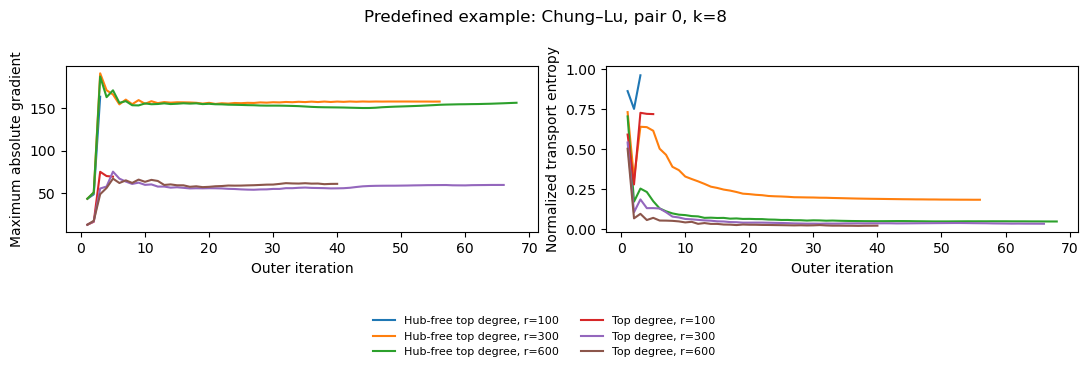

In [6]:
initial_fields = ['first_gradient_max_abs', 'first_gradient_p95_abs', 'first_gradient_p95_over_max',
                  'first_seed_term_norm_fraction']
variation = valid.groupby(['model', 'pair_index', 'budget', 'rule'])[initial_fields].agg(lambda s: s.max()-s.min())
if (variation.fillna(0).abs() > 1e-8).any().any():
    print('CHECK FAILED: first gradients differ across regularizers despite fixed initialization.')
    display(variation)
else:
    print('PASS: first-gradient diagnostics agree across all available regularizers for each fixed seed set.')

display(valid.groupby(['model', 'budget', 'regularizer', 'rule'])[
    ['first_gradient_max_abs', 'first_gradient_p95_over_max', 'first_epsilon_magnitude',
     'first_seed_term_norm_fraction', 'first_transport_entropy', 'final_soft_entropy']].mean().round(4))

if not trace.empty:
    # An illustrative trajectory fixed in advance, rather than selected for an interesting outcome.
    model, pair_index, budget = models_present[0], PAIR_INDICES[0], budgets_present[0]
    example = trace[(trace['model'] == model) & (trace['pair_index'] == pair_index) & (trace['budget'] == budget)]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    for (rule, regularizer), group in example.groupby(['rule', 'regularizer']):
        group = group.sort_values('iteration')
        label = f'{audit.LABELS[rule]}, r={regularizer:g}'
        axes[0].plot(group['iteration'], group['gradient_max_abs'], label=label)
        axes[1].plot(group['iteration'], group['transport_entropy'], label=label)
    axes[0].set(xlabel='Outer iteration', ylabel='Maximum absolute gradient')
    axes[1].set(xlabel='Outer iteration', ylabel='Normalized transport entropy', ylim=(-.02, 1.02))
    handles, labels = axes[1].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False, fontsize=8)
    fig.suptitle(f'Predefined example: {audit.MODEL_LABELS[model]}, pair {pair_index}, k={budget}')
    fig.tight_layout(rect=(0,.20,1,.95))
    save_figure(fig, 'iteration_diagnostics')
    plt.show()


## 6. Interpretation and next decision

- **The hub-free accuracy advantage persists over numerically clean regularizers:** hub avoidance is robust to this tested range; temperature alone has not explained it.
- **Top degree catches up at another clean regularizer:** part of the earlier advantage may depend on solver tuning. Confirm that choice on fresh pairs, with one common regularizer per setting.
- **Only final entropy changes:** soft confidence can change without improving matching. Do not equate sharpness with correctness.
- **Large seed-dependent changes in the first gradient maximum, compressed bulk scores, and different transport entropy:** consistent with the proposed scaling mechanism, but not proof. A later controlled comparison of gradient normalizations would be needed to isolate that cause.
- **Accuracy changes coincide with warnings, poor transport marginals or iteration limits:** resolve numerical convergence before attributing the change to seed quality or temperature.

This audit reuses known pairs and compares a small fixed budget grid. It is a diagnostic, not a search for an optimal regularizer, a deployed stopping policy, or a guarantee across graph families. It adds no new seed queries beyond the fixed simulated sets. No production solver or preset is changed.

**Outputs:** exact pair archives, seed lists, settings/source/version records, one JSON per solver call with full final permutation and iteration trace, aggregate CSVs, and figures. To add pairs, increase `PAIR_INDICES` and rerun; keep all other settings fixed. To broaden the regularizer grid or change tolerances, use a new output directory.
